# 05-Extracción de Características

## Objetivo

Convertir cada imagen en un vector de características numéricas que describan la forma y el color de la lesión segmentada. Estas características son la entrada del modelo baseline.

## 1. Importación de librerías y carga de las muestras

In [9]:
import sys
sys.path.append("..")

import math
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm

from src.preprocesamiento import cargar, procesar

PROCESSED = Path("../data/processed")
train_df = pd.read_csv(PROCESSED / "train.csv")
test_df = pd.read_csv(PROCESSED / "test.csv")
print(train_df.shape, test_df.shape)

(982, 9) (246, 9)


## 2. Caracteristicas geometriacs

Se calcula la mascara de la lesion.

In [10]:
def caracteristicas_geometricas(mascara, valida):
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if not contornos:
        return None
    cnt = max(contornos, key=cv2.contourArea)

    area = cv2.contourArea(cnt)
    perimetro = cv2.arcLength(cnt, True)
    if area == 0 or perimetro == 0:
        return None

    # Comprobamos la circularidad 1 para los circulos perfectos, y disminuye a medida que la forma se aleja a la de uncirculo. Se calcula como 4π * área / perímetro²
    circularidad = 4 * math.pi * area / perimetro ** 2

    # Baja si el borde tiene muescas
    casco = cv2.convexHull(cnt)
    solidez = area / cv2.contourArea(casco)

    # Se compara la lesión con su reflejo horizontal y vertical
    x, y, w, h = cv2.boundingRect(cnt)
    recorte = (mascara[y:y + h, x:x + w] > 0).astype(np.uint8)
    inter_h = (recorte & np.fliplr(recorte)).sum()
    inter_v = (recorte & np.flipud(recorte)).sum()
    asimetria = 1 - (inter_h + inter_v) / (2 * recorte.sum())

    return {
        "area": area,
        "area_rel": area / (valida > 0).sum(),
        "perimetro": perimetro,
        "circularidad": circularidad,
        "solidez": solidez,
        "asimetria": asimetria,
    }

## 3. Caracteristicas de color

Esto lo miramos porque los melanomas tieden a tener irregularidades en el color.

In [11]:
def caracteristicas_color(img_rgb, mascara):
    dentro = mascara > 0
    espacios = {
        "hsv": cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV),
        "lab": cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB),
    }
    salida = {}
    for nombre, im in espacios.items():
        for i in range(3):
            valores = im[..., i][dentro].astype(float)
            salida[f"{nombre}{i + 1}_media"] = valores.mean()
            salida[f"{nombre}{i + 1}_desvio"] = valores.std()
    return salida


def extraer(image_id):
    img = cargar(image_id)
    limpia, _, valida, lesion = procesar(img)
    geo = caracteristicas_geometricas(lesion, valida)
    if geo is None:
        return None
    return {**geo, **caracteristicas_color(limpia, lesion)}

## 4. Estraccion para train y test

In [12]:
def construir_tabla(df):
    filas, fallidas = [], []
    for _, f in tqdm(df.iterrows(), total=len(df)):
        c = extraer(f["image_id"])
        if c is None:
            fallidas.append(f["image_id"])
            continue
        filas.append({"image_id": f["image_id"], "etiqueta": f["etiqueta"], **c})
    return pd.DataFrame(filas), fallidas

X_train, fallidas_train = construir_tabla(train_df)
X_test, fallidas_test = construir_tabla(test_df)

print("Train:", X_train.shape, "| fallidas:", len(fallidas_train))
print("Test:", X_test.shape, "| fallidas:", len(fallidas_test))

X_train.to_csv(PROCESSED / "features_train.csv", index=False)
X_test.to_csv(PROCESSED / "features_test.csv", index=False)

100%|██████████| 246/246 [00:30<00:00,  8.15it/s]


Train: (982, 20) | fallidas: 0
Test: (246, 20) | fallidas: 0


## 5. Revision de las caracteristicas en train

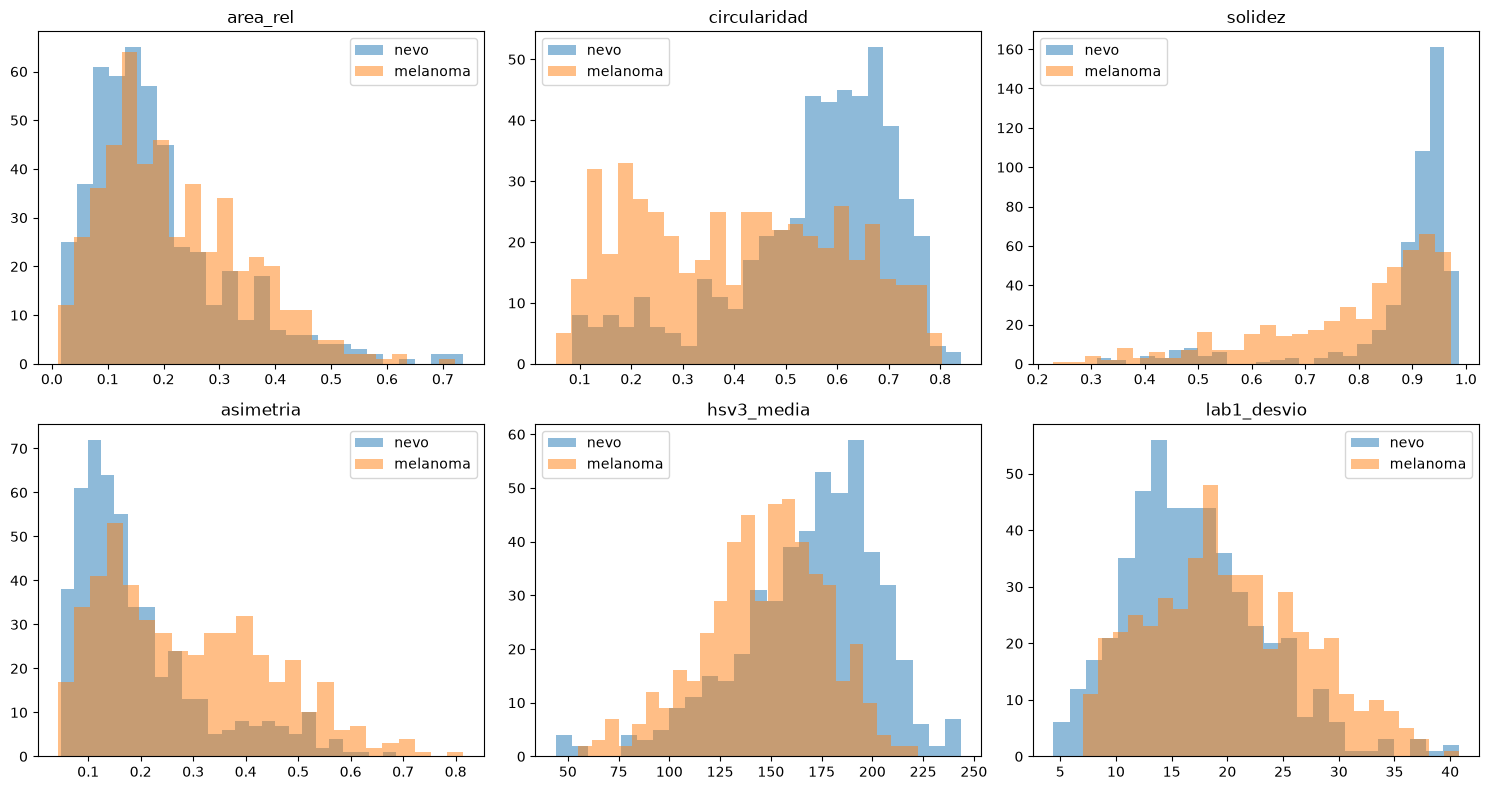

etiqueta               0           1
area_rel        0.190519    0.220260
circularidad    0.552464    0.407067
solidez         0.879878    0.785251
asimetria       0.193616    0.288864
hsv3_media    169.331746  146.725575
lab1_desvio    17.040142   20.185260


In [13]:
cols = ["area_rel", "circularidad", "solidez", "asimetria", "hsv3_media", "lab1_desvio"]
fig, axs = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axs.ravel(), cols):
    for et, nombre in [(0, "nevo"), (1, "melanoma")]:
        ax.hist(X_train[X_train["etiqueta"] == et][c], bins=25, alpha=0.5, label=nombre)
    ax.set_title(c)
    ax.legend()
plt.tight_layout()
plt.show()

print(X_train.groupby("etiqueta")[cols].mean().T)

123 {1: 96, 0: 27}


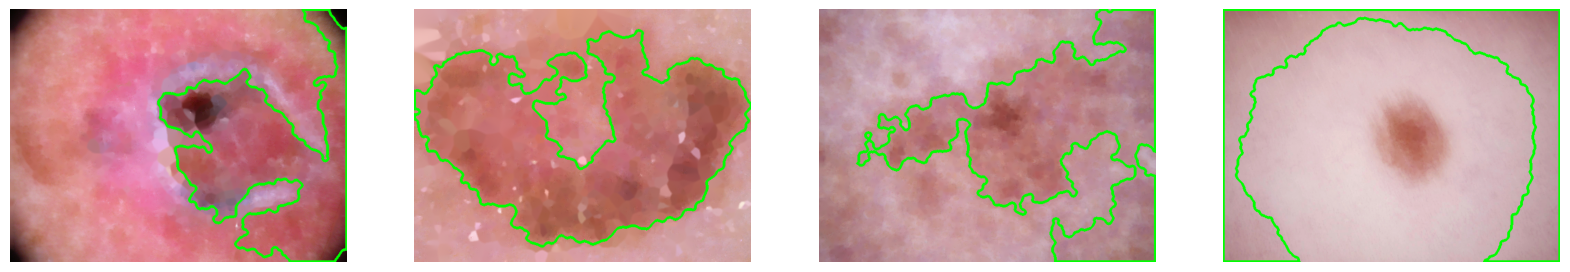

In [14]:
import random
bajas = X_train[X_train["circularidad"] < 0.2]
print(len(bajas), bajas["etiqueta"].value_counts().to_dict())

ids = bajas["image_id"].sample(4, random_state=1)
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, i in zip(axs, ids):
    img = cargar(i)
    limpia, _, valida, lesion = procesar(img)
    contornos, _ = cv2.findContours(lesion, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    salida = limpia.copy()
    cv2.drawContours(salida, contornos, -1, (0, 255, 0), 3)
    ax.imshow(salida)
    ax.axis("off")
plt.show()